In [21]:
import pandas as pd
import numpy as np

In [22]:
df =pd.read_csv("cleaned_data.csv")
df

,Unnamed: 0,order_id,distance_km,item_count,peak_hour,weather,delivery_minutes,data_issue
0,0,O101,3.2,2.0,False,Clear,32.0,False
1,1,O102,5.5,4.0,True,Rain,48.0,False
2,2,O103,2.0,1.0,False,Clear,25.0,False
3,3,O104,6.1,3.0,True,Rain,42.0,False
4,4,O105,4.0,2.0,False,Cloudy,38.0,False
5,5,O106,8.0,5.0,True,Rain,61.0,False
6,6,O107,0.0,2.0,False,Clear,29.0,True
7,7,O108,3.8,0.0,True,cloudy,40.0,True
8,8,O109,7.2,4.0,True,Clear,55.0,False
9,9,O110,1.5,1.0,False,Clear,20.0,False


calculate the mean and median delivery time with NumPy

In [23]:
delivery = df["delivery_minutes"].to_numpy()

mean_delivery = np.mean(delivery)
median_delivery = np.median(delivery)

print(F"Mean delivery: {mean_delivery:.2f}minutes")
print(F"Median delivery: {median_delivery:.2f}minutes")

Mean delivery: 35.45minutes
Median delivery: 38.00minutes


calculate the correlation between distance and delivery time

In [24]:
distance = df["distance_km"].to_numpy()

correlation = np.corrcoef(
    distance,
    delivery
)[0,1]

print(f"Correlation: {correlation:.3f}")

Correlation: 0.593


create a scatter plot of distance versus delivery time

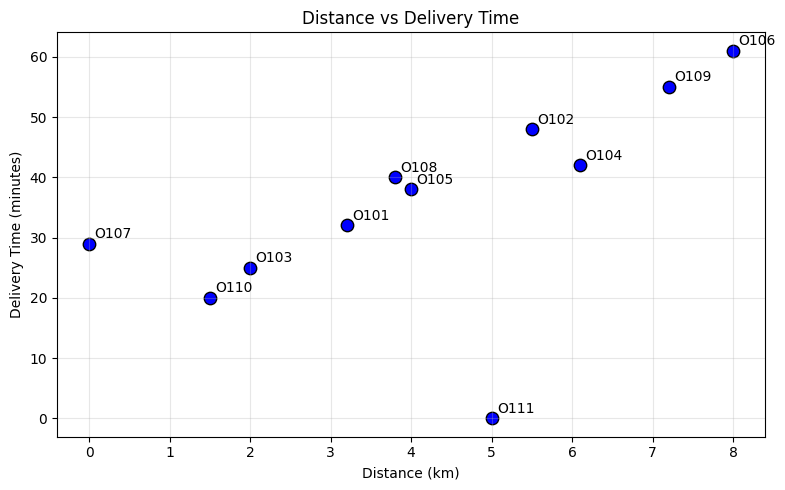

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(
    df["distance_km"],
    df["delivery_minutes"],
    color="b",
    s=80,
    edgecolors="black"
)

for _, row in df.iterrows():
    plt.annotate(
        row["order_id"],
        (
            row["distance_km"],
            row["delivery_minutes"]
        ),
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

create a bar chart comparing average delivery time during peak and non-peak hours

In [26]:
peak_hour = df["peak_hour"].to_numpy(
    dtype=bool
)

peak_average = np.mean(
    delivery[peak_hour]
)

non_peak_average = np.mean(
    delivery[~peak_hour]
    
)

print(f"Peak-hour average: {peak_average:.2f}")
print(f"Non-peak average: {non_peak_average:.2f}")

Peak-hour average: 41.00
Non-peak average: 28.80


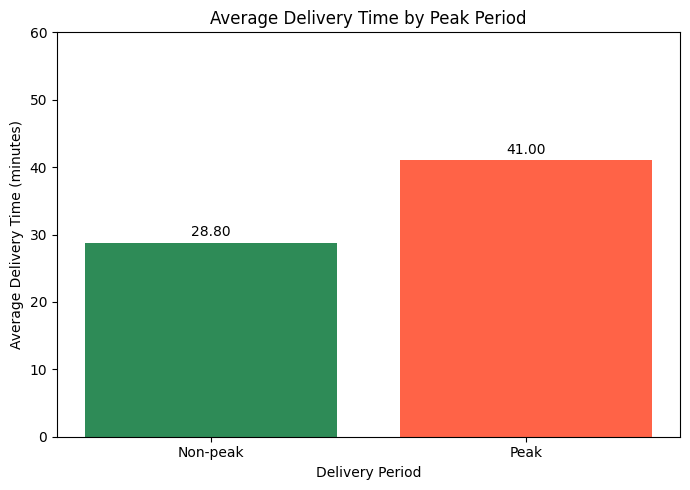

In [27]:
labels = ["Non-peak","Peak"]
averages = [non_peak_average, peak_average]

plt.figure(figsize=(7,5))

bars = plt.bar(
    labels,
    averages,
    color=["seagreen","tomato"]
)

plt.title("Average Delivery Time by Peak Period")
plt.xlabel("Delivery Period")
plt.ylabel("Average Delivery Time (minutes)")
plt.ylim(0, 60)

for bar, value in zip(bars, averages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()